# Normalización de parches y aplicación de métricas

## Celda 1 — Importar librerías

In [ ]:
import os
import sys
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from skimage.metrics import structural_similarity
from skimage.color import rgb2lab, deltaE_ciede2000
from skimage import io
from PIL import Image
from tiatoolbox.tools import stainnorm
from wsi_normalizer import imread as wsi_imread, VahadaneNormalizer as WsiVahadane

# ── Importar módulos propios de algoritmos ────────────────────────────────
# Ajustá esta ruta si cambiás la ubicación del paquete algoritmos
DIR_BASE = 'C:/Users/admin2/Desktop/Fuentes_tesis/'
sys.path.append(DIR_BASE)

from algoritmos.acd_zheng  import StainNormalizerACD
from algoritmos.scan_salvi import StainNormalizerSCAN

import tiatoolbox, sklearn, tensorflow as tf
print(f' NumPy         : {np.__version__}')
print(f' TensorFlow    : {tf.__version__}')
print(f' tiatoolbox    : {tiatoolbox.__version__}')
print(f' wsi-normalizer: OK')
print(f' scikit-learn  : {sklearn.__version__}')
print(f' Módulo ACD    : OK')
print(f' Módulo SCAN   : OK')

|2026-08-15|15:24:12.333| [WARNING] From C:\Users/admin2/Desktop/Fuentes_tesis\algoritmos\acd_zheng.py:24: The name tf.disable_eager_execution is deprecated. Please use tf.compat.v1.disable_eager_execution instead.



ImportError: cannot import name 'StainNormalizerACD' from 'algoritmos.acd_zheng' (C:\Users/admin2/Desktop/Fuentes_tesis\algoritmos\acd_zheng.py)

## Celda 2 — Configurar rutas

In [ ]:
# ─── EDITÁ ESTAS RUTAS ─────────────────────────────────────────────────────

# Ruta del parche target (imagen de referencia)
RUTA_TARGET = 'C:/Users/admin2/Desktop/Fuentes_tesis/target/target.png'

# Directorio raíz donde están las carpetas lamina_1/, lamina_2/, etc.
DIR_PARCHES = 'C:/Users/admin2/Desktop/Fuentes_tesis/parches/'

# Directorio donde se guardarán las imágenes normalizadas y el CSV
DIR_SALIDA  = 'C:/Users/admin2/Desktop/Fuentes_tesis/normalizado/'

# ───────────────────────────────────────────────────────────────────────────

os.makedirs(DIR_SALIDA, exist_ok=True)

assert os.path.exists(RUTA_TARGET), f' Target no encontrado: {RUTA_TARGET}'

carpetas_laminas = sorted([
    d for d in os.listdir(DIR_PARCHES)
    if os.path.isdir(os.path.join(DIR_PARCHES, d)) and d.startswith('lamina')
])

assert len(carpetas_laminas) > 0, f' No se encontraron carpetas lamina* en {DIR_PARCHES}'

print(f' TARGET        : {RUTA_TARGET}')
print(f' DIR_PARCHES   : {DIR_PARCHES}')
print(f' DIR_SALIDA    : {DIR_SALIDA}')
print(f'\n Láminas encontradas ({len(carpetas_laminas)}):')
for c in carpetas_laminas:
    patches = [f for f in os.listdir(os.path.join(DIR_PARCHES, c))
               if f.endswith('.png') and f.startswith('pat_')]
    print(f'   → {c}/ — {len(patches)} patches')

✔ TARGET        : C:/Users/admin2/Desktop/Fuentes_tesis/target/target.png
✔ DIR_PARCHES   : C:/Users/admin2/Desktop/Fuentes_tesis/parches/
✔ DIR_SALIDA    : C:/Users/admin2/Desktop/Fuentes_tesis/normalizado/

✔ Láminas encontradas (4):
   → lamina_1/ — 20 patches
   → lamina_3/ — 20 patches
   → lamina_4/ — 20 patches
   → lamina_5/ — 20 patches


## Celda 3 — Cargar target y pre-entrenar normalizadores

In [ ]:
# Cargar target en los formatos requeridos por cada librería
target_img = io.imread(RUTA_TARGET)[:, :, :3].astype(np.uint8)
target_wsi = wsi_imread(RUTA_TARGET)
target_acd = target_img[np.newaxis, ...]   # formato (1, H, W, 3) para ACD

print(f' Target cargado: {target_img.shape} — dtype: {target_img.dtype}')

# Pre-entrenar normalizadores con el target (una sola vez)
print('\n Entrenando Reinhard...', end=' ')
norm_reinhard = stainnorm.get_normalizer('Reinhard')
norm_reinhard.fit(target_img)
print('OK')

print(' Entrenando Vahadane (wsi)...', end=' ')
norm_vahadane = WsiVahadane()
norm_vahadane.fit(target_wsi)
print('OK')

print(' Entrenando ACD (Zheng)...', end=' ')
norm_acd = StainNormalizerACD(eta=0.4, gamma=0.6)
norm_acd.fit(target_acd)
print('OK')

print(' Entrenando SCAN (Salvi)...', end=' ')
norm_scan = StainNormalizerSCAN()
norm_scan.fit(target_img)
print('OK')

print('\n Todos los normalizadores listos')

✔ Target cargado: (1024, 2048, 3) — dtype: uint8

▶ Entrenando Reinhard... OK
▶ Entrenando Vahadane (wsi)... OK
▶ Entrenando ACD (Zheng)... OK
▶ Entrenando SCAN (Salvi)... OK

✔ Todos los normalizadores listos


## Celda 4 — Funciones de métricas

In [12]:
def calcular_delta_e(img1, img2):
    """
    ΔE CIEDE2000 entre dos imágenes usando medianas de canales Lab.
    No requiere mismo contenido espacial.
    Menor valor = colores más similares.
    """
    lab1 = rgb2lab(img1 / 255.0)
    lab2 = rgb2lab(img2 / 255.0)
    med1 = np.median(lab1.reshape(-1, 3), axis=0)
    med2 = np.median(lab2.reshape(-1, 3), axis=0)
    return float(deltaE_ciede2000(med1.reshape(1,1,3), med2.reshape(1,1,3))[0,0])

def calcular_ssim(source_img, norm_img):
    """
    SSIM Source: similitud estructural entre imagen normalizada y fuente original.
    Mide preservación morfológica. Mayor valor = mejor preservación.
    """
    s_gray = np.mean(source_img, axis=2).astype(np.uint8)
    n_gray = np.mean(norm_img,   axis=2).astype(np.uint8)
    return float(structural_similarity(s_gray, n_gray, data_range=255))

print(' Funciones de métricas definidas')

✔ Funciones de métricas definidas


## Celda 5 — Procesamiento multi-patch

In [14]:
registros = []

# Acumuladores de tiempo por algoritmo
tiempos = {
    'reinhard': [],
    'vahadane': [],
    'zheng'   : [],
    'salvi'   : [],
}

print('=' * 70)
print('  NORMALIZACIÓN Y EVALUACIÓN MULTI-PATCH')
print('=' * 70)

for carpeta in carpetas_laminas:

    nro_lamina = carpeta.replace('lamina_', '').replace('lamina', '')
    dir_lamina = os.path.join(DIR_PARCHES, carpeta)

    dir_salida_lamina = os.path.join(DIR_SALIDA, f'lamina_{nro_lamina}')
    os.makedirs(dir_salida_lamina, exist_ok=True)

    patches = sorted([
        f for f in os.listdir(dir_lamina)
        if f.endswith('.png') and f.startswith('pat_')
    ])

    print(f'\n Lámina {nro_lamina} — {len(patches)} patches')

    for patch_file in patches:

        partes    = patch_file.replace('.png', '').split('_')
        nro_patch = partes[1]

        ruta_patch = os.path.join(dir_lamina, patch_file)
        source_img = io.imread(ruta_patch)[:, :, :3].astype(np.uint8)
        source_wsi = wsi_imread(ruta_patch)
        source_acd = source_img[np.newaxis, ...]

        print(f'   Patch {nro_patch}...', end=' ')

        delta_e_baseline = calcular_delta_e(source_img, target_img)

        registro = {
            'lamina'          : nro_lamina,
            'patch'           : patch_file,
            'delta_e_baseline': round(delta_e_baseline, 4),
        }

        # ── Reinhard ──────────────────────────────────────────────────
        try:
            t0       = time.time()
            norm_img = norm_reinhard.transform(source_img.copy())
            elapsed  = time.time() - t0
            tiempos['reinhard'].append(elapsed)
            nombre_out = f'pat_{nro_patch}_{nro_lamina}_reinhard.png'
            Image.fromarray(norm_img).save(
                os.path.join(dir_salida_lamina, nombre_out),
                format='PNG', compress_level=9
            )
            registro['ssim_reinhard']    = round(calcular_ssim(source_img, norm_img), 4)
            registro['delta_e_reinhard'] = round(calcular_delta_e(norm_img, target_img), 4)
            registro['tiempo_reinhard']  = round(elapsed, 4)
        except Exception as e:
            registro['ssim_reinhard']    = None
            registro['delta_e_reinhard'] = None
            registro['tiempo_reinhard']  = None

        # ── Vahadane (wsi) ────────────────────────────────────────────
        try:
            t0       = time.time()
            norm_img = np.clip(norm_vahadane.transform(source_wsi), 0, 255).astype(np.uint8)
            elapsed  = time.time() - t0
            tiempos['vahadane'].append(elapsed)
            nombre_out = f'pat_{nro_patch}_{nro_lamina}_vahadane.png'
            Image.fromarray(norm_img).save(
                os.path.join(dir_salida_lamina, nombre_out),
                format='PNG', compress_level=9
            )
            registro['ssim_vahadane']    = round(calcular_ssim(source_img, norm_img), 4)
            registro['delta_e_vahadane'] = round(calcular_delta_e(norm_img, target_img), 4)
            registro['tiempo_vahadane']  = round(elapsed, 4)
        except Exception as e:
            registro['ssim_vahadane']    = None
            registro['delta_e_vahadane'] = None
            registro['tiempo_vahadane']  = None

        # ── ACD (Zheng) ───────────────────────────────────────────────
        try:
            t0       = time.time()
            norm_raw = norm_acd.transform(source_acd)
            norm_img = np.clip(norm_raw[0], 0, 255).astype(np.uint8)
            elapsed  = time.time() - t0
            tiempos['zheng'].append(elapsed)
            nombre_out = f'pat_{nro_patch}_{nro_lamina}_zheng.png'
            Image.fromarray(norm_img).save(
                os.path.join(dir_salida_lamina, nombre_out),
                format='PNG', compress_level=9
            )
            registro['ssim_zheng']    = round(calcular_ssim(source_img, norm_img), 4)
            registro['delta_e_zheng'] = round(calcular_delta_e(norm_img, target_img), 4)
            registro['tiempo_zheng']  = round(elapsed, 4)
        except Exception as e:
            registro['ssim_zheng']    = None
            registro['delta_e_zheng'] = None
            registro['tiempo_zheng']  = None

        # ── SCAN (Salvi) ──────────────────────────────────────────────
        try:
            t0       = time.time()
            norm_img = norm_scan.transform(source_img)
            elapsed  = time.time() - t0
            tiempos['salvi'].append(elapsed)
            nombre_out = f'pat_{nro_patch}_{nro_lamina}_salvi.png'
            Image.fromarray(norm_img).save(
                os.path.join(dir_salida_lamina, nombre_out),
                format='PNG', compress_level=9
            )
            registro['ssim_salvi']    = round(calcular_ssim(source_img, norm_img), 4)
            registro['delta_e_salvi'] = round(calcular_delta_e(norm_img, target_img), 4)
            registro['tiempo_salvi']  = round(elapsed, 4)
        except Exception as e:
            registro['ssim_salvi']    = None
            registro['delta_e_salvi'] = None
            registro['tiempo_salvi']  = None

        registros.append(registro)
        print('OK')

print(f'\n Procesamiento completo — {len(registros)} patches procesados')

KeyboardInterrupt: 

## Celda 6 — Calcular medianas y exportar CSV

In [ ]:
df = pd.DataFrame(registros)

cols_numericas = [
    'delta_e_baseline',
    'ssim_reinhard',    'delta_e_reinhard',  'tiempo_reinhard',
    'ssim_vahadane',    'delta_e_vahadane',  'tiempo_vahadane',
    'ssim_zheng',       'delta_e_zheng',     'tiempo_zheng',
    'ssim_salvi',       'delta_e_salvi',     'tiempo_salvi',
]

medianas = df[cols_numericas].median()

# Tiempos medianos por algoritmo
t_reinhard = np.median(tiempos['reinhard'])
t_vahadane = np.median(tiempos['vahadane'])
t_zheng    = np.median(tiempos['zheng'])
t_salvi    = np.median(tiempos['salvi'])

# Agregar fila de medianas al CSV
fila_mediana = {'lamina': 'MEDIANA', 'patch': '---'}
for col in cols_numericas:
    fila_mediana[col] = round(medianas[col], 4)

df_final = pd.concat([df, pd.DataFrame([fila_mediana])], ignore_index=True)

ruta_csv = os.path.join(DIR_SALIDA, 'resultados_normalizacion.csv')
df_final.to_csv(ruta_csv, index=False)
print(f' CSV guardado en: {ruta_csv}')

# Tabla resumen en consola
print('\n' + '=' * 70)
print('  MEDIANAS GLOBALES POR ALGORITMO')
print('=' * 70)
print(f'  ΔE Baseline (antes de normalizar): {medianas["delta_e_baseline"]:.4f}')
print('─' * 70)
print(f"  {'Algoritmo':<20} {'SSIM Source':>12} {'ΔE CIEDE2000':>14} {'Tiempo (s)':>12}")
print('─' * 70)
algoritmos_info = [
    ('Reinhard',       'ssim_reinhard',  'delta_e_reinhard',  t_reinhard),
    ('Vahadane (wsi)', 'ssim_vahadane',  'delta_e_vahadane',  t_vahadane),
    ('ACD (Zheng)',    'ssim_zheng',     'delta_e_zheng',     t_zheng),
    ('SCAN (Salvi)',   'ssim_salvi',     'delta_e_salvi',     t_salvi),
]
for nombre, col_ssim, col_de, t_med in algoritmos_info:
    print(f"  {nombre:<20} {medianas[col_ssim]:>12.4f} {medianas[col_de]:>14.4f} {t_med:>12.4f}")
print('─' * 70)
print('  ↑ SSIM más alto = mejor preservación morfológica')
print('  ↓ ΔE más bajo   = mejor transferencia de color')
print('  ↓ Tiempo menor  = más eficiente')

✔ CSV guardado en: C:/Users/admin2/Desktop/Fuentes_tesis/normalizado/resultados_normalizacion.csv

  MEDIANAS GLOBALES POR ALGORITMO
  ΔE Baseline (antes de normalizar): 14.4398
──────────────────────────────────────────────────────────────────────
  Algoritmo             SSIM Source   ΔE CIEDE2000   Tiempo (s)
──────────────────────────────────────────────────────────────────────
  Reinhard                   0.9161         1.4814       0.1475
  Vahadane (wsi)             0.9514         5.5851       3.8863
  ACD (Zheng)                0.9730         5.2578       2.2986
  SCAN (Salvi)               0.9645        14.5014       5.1128
──────────────────────────────────────────────────────────────────────
  ↑ SSIM más alto = mejor preservación morfológica
  ↓ ΔE más bajo   = mejor transferencia de color
  ↓ Tiempo menor  = más eficiente


## Celda 7 — Gráfico comparativo

✔ Gráfico guardado en: C:/Users/admin2/Desktop/Fuentes_tesis/normalizado/grafico_comparativo_medianas.png


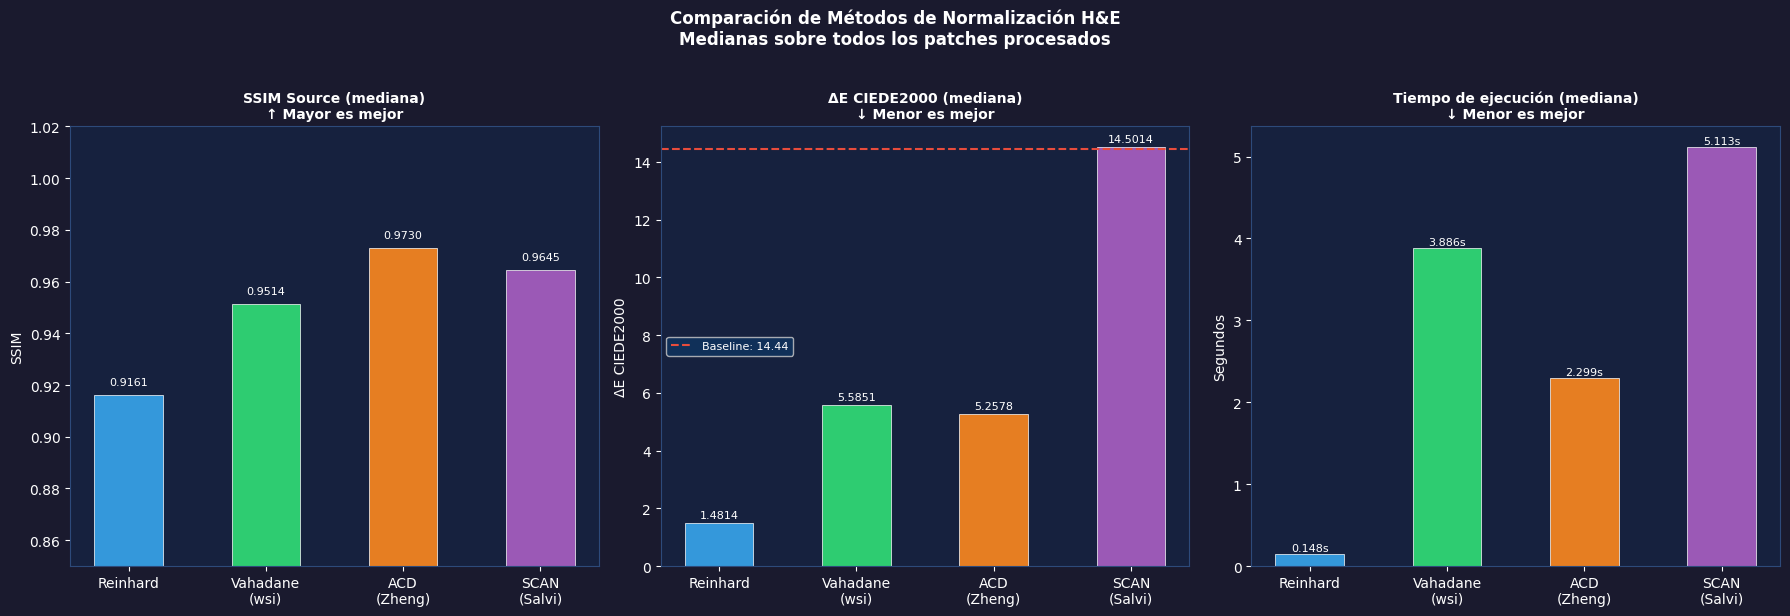

In [ ]:
# ── Preparar datos por algoritmo ─────────────────────────────────────────
colores  = ['#3498db', '#2ecc71', '#e67e22', '#9b59b6']
nombres  = ['Reinhard', 'Vahadane\n(wsi)', 'ACD\n(Zheng)', 'SCAN\n(Salvi)']
baseline = medianas['delta_e_baseline']

# Datos de SSIM por algoritmo (excluir fila MEDIANA)
df_data = df[df['lamina'] != 'MEDIANA'].copy()

ssim_data = [
    df_data['ssim_reinhard'].dropna().values,
    df_data['ssim_vahadane'].dropna().values,
    df_data['ssim_zheng'].dropna().values,
    df_data['ssim_salvi'].dropna().values,
]
de_data = [
    df_data['delta_e_reinhard'].dropna().values,
    df_data['delta_e_vahadane'].dropna().values,
    df_data['delta_e_zheng'].dropna().values,
    df_data['delta_e_salvi'].dropna().values,
]
t_data = [
    df_data['tiempo_reinhard'].dropna().values,
    df_data['tiempo_vahadane'].dropna().values,
    df_data['tiempo_zheng'].dropna().values,
    df_data['tiempo_salvi'].dropna().values,
]

# ── Configuración de estilo ───────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
fig.patch.set_facecolor('#1a1a2e')

def estilo_ax(ax, titulo, ylabel):
    ax.set_facecolor('#16213e')
    ax.set_title(titulo, color='white', fontsize=10, fontweight='bold')
    ax.set_ylabel(ylabel, color='white')
    ax.tick_params(colors='white')
    ax.spines[:].set_color('#2d4a7a')
    ax.yaxis.label.set_color('white')

def agregar_estadisticas(ax, datos, posiciones):
    """Agrega etiquetas de media y desviación estándar sobre cada boxplot."""
    for i, (pos, d) in enumerate(zip(posiciones, datos)):
        media = np.mean(d)
        std   = np.std(d)
        ax.text(pos, ax.get_ylim()[1] * 0.98,
                f'x̄={media:.3f}\nσ={std:.3f}',
                ha='center', va='top', color='white',
                fontsize=7.5, linespacing=1.4)

posiciones = [1, 2, 3, 4]
etiquetas  = ['Reinhard', 'Vahadane\n(wsi)', 'ACD\n(Zheng)', 'SCAN\n(Salvi)']

def boxplot_coloreado(ax, datos, colores, posiciones):
    """Dibuja boxplots con colores individuales por algoritmo."""
    for i, (d, c, pos) in enumerate(zip(datos, colores, posiciones)):
        bp = ax.boxplot(
            d, positions=[pos], widths=0.5,
            patch_artist=True,
            showfliers=True,
            flierprops=dict(marker='o', markerfacecolor=c,
                            markersize=4, linestyle='none',
                            markeredgecolor='white', markeredgewidth=0.5),
            boxprops=dict(facecolor=c + '55', color=c, linewidth=1.5),
            medianprops=dict(color='white', linewidth=2),
            whiskerprops=dict(color=c, linewidth=1.2, linestyle='--'),
            capprops=dict(color=c, linewidth=1.5),
        )
        # Marcar la media con un triángulo
        media = np.mean(d)
        ax.plot(pos, media, marker='^', color='white',
                markersize=7, zorder=5, label='Media' if i == 0 else '')

# ── Gráfico 1: SSIM Source ────────────────────────────────────────────────
boxplot_coloreado(axes[0], ssim_data, colores, posiciones)
estilo_ax(axes[0], 'SSIM Source\n↑ Mayor es mejor — Preservación morfológica', 'SSIM')
axes[0].set_xticks(posiciones)
axes[0].set_xticklabels(etiquetas, color='white', fontsize=8)
axes[0].set_ylim(0.2, 1.12)
agregar_estadisticas(axes[0], ssim_data, posiciones)

# ── Gráfico 2: ΔE CIEDE2000 ───────────────────────────────────────────────
boxplot_coloreado(axes[1], de_data, colores, posiciones)
axes[1].axhline(y=float(baseline), color='#e74c3c', linestyle='--',
                linewidth=1.5, label=f'Baseline ΔE: {baseline:.2f}')
estilo_ax(axes[1], 'ΔE CIEDE2000\n↓ Menor es mejor — Transferencia de color', 'ΔE CIEDE2000')
axes[1].set_xticks(posiciones)
axes[1].set_xticklabels(etiquetas, color='white', fontsize=8)
axes[1].legend(facecolor='#0f3460', labelcolor='white', fontsize=8)
agregar_estadisticas(axes[1], de_data, posiciones)

# ── Gráfico 3: Tiempo de ejecución ────────────────────────────────────────
boxplot_coloreado(axes[2], t_data, colores, posiciones)
estilo_ax(axes[2], 'Tiempo de ejecución\n↓ Menor es mejor — Eficiencia', 'Segundos')
axes[2].set_xticks(posiciones)
axes[2].set_xticklabels(etiquetas, color='white', fontsize=8)
agregar_estadisticas(axes[2], t_data, posiciones)

# ── Leyenda global ────────────────────────────────────────────────────────
legend_elements = [
    mpatches.Patch(facecolor=c + '55', edgecolor=c, label=n.replace('\\n', ' '))
    for c, n in zip(colores, ['Reinhard', 'Vahadane (wsi)', 'ACD (Zheng)', 'SCAN (Salvi)'])
]
legend_elements.append(
    plt.Line2D([0], [0], marker='^', color='white', markersize=7,
               linestyle='none', label='Media (▲)')
)
legend_elements.append(
    plt.Line2D([0], [0], color='white', linewidth=2, label='Mediana (─)')
)
fig.legend(handles=legend_elements, loc='lower center', ncol=6,
           facecolor='#0f3460', labelcolor='white', fontsize=8,
           bbox_to_anchor=(0.5, -0.05))

fig.suptitle(
    'Comparación de Métodos de Normalización H&E\n'
    'Boxplots sobre todos los patches procesados (▲ = media, — = mediana)',
    color='white', fontsize=12, fontweight='bold', y=1.02
)
plt.tight_layout()

ruta_fig = os.path.join(DIR_SALIDA, 'grafico_comparativo_boxplot.png')
plt.savefig(ruta_fig, dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
print(f'✔ Gráfico guardado en: {ruta_fig}')
plt.show()